# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
# Mostrar la codificación con LabelEncoder
print("Codificación con LabelEncoder:")
display(data[['sex', 'sex_label']].head(10))

# Mostrar la codificación con One-Hot Encoding
print("Codificación con One-Hot Encoding:")
display(onehot_encoder.head(10))

Codificación con LabelEncoder:


,sex,sex_label
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1
5,male,1
6,male,1
7,male,1
8,female,0
9,female,0


Codificación con One-Hot Encoding:


,embarked_C,embarked_Q,embarked_S
0,False,False,True
1,True,False,False
2,False,False,True
3,False,False,True
4,False,False,True
5,False,True,False
6,False,False,True
7,False,False,True
8,False,False,True
9,True,False,False


In [ ]:
La principal diferencia entre LabelEncoder y OneHotEncoder es la manera en que transforman las variables categóricas.

LabelEncoder asigna un número entero a cada categoría. En nuestro ejemplo, convirtió female en 0 y male en 1, utilizando una sola columna para representar los datos.

Por otro lado, OneHotEncoder crea una columna independiente para cada categoría. En nuestro ejemplo, creó tres columnas para representar los puertos de embarque C, Q y S, utilizando valores booleanos (True y False).

La ventaja de LabelEncoder es que ocupa menos espacio, mientras que OneHotEncoder evita establecer relaciones de orden entre categorías que no tienen una jerarquía natural.

### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

In [10]:
import matplotlib.pyplot as plt

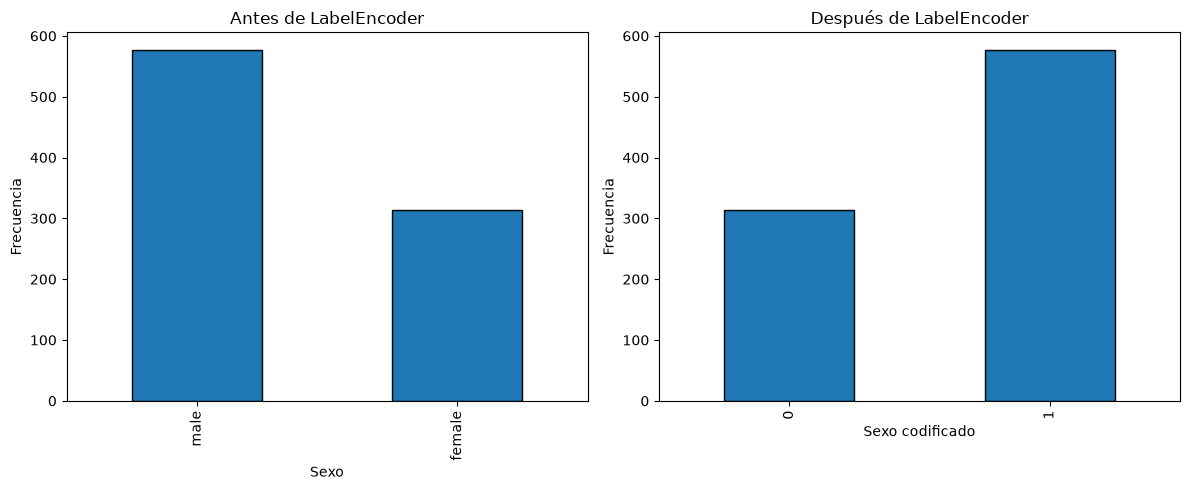

In [11]:
# Crear figura con dos gráficas
plt.figure(figsize=(12, 5))

# Gráfica 1: Frecuencias originales
plt.subplot(1, 2, 1)

data['sex'].value_counts().plot(kind='bar', edgecolor='black')

plt.title('Antes de LabelEncoder')
plt.xlabel('Sexo')
plt.ylabel('Frecuencia')

# Gráfica 2: Frecuencias después de LabelEncoder
plt.subplot(1, 2, 2)

data['sex_label'].value_counts().sort_index().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Después de LabelEncoder')
plt.xlabel('Sexo codificado')
plt.ylabel('Frecuencia')

# Mostrar gráficas
plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [ ]:
Convierte categorías de texto en valores numéricos.
Evita establecer una jerarquía numérica artificial entre categorías.
Facilita el procesamiento de variables categóricas por muchos algoritmos de Machine Learning.

In [12]:
# Aplicar One-Hot Encoding a la columna class
class_encoded = pd.get_dummies(data['class'], prefix='class')

# Mostrar los resultados
print("Codificación de la columna class:")
display(class_encoded.head(10))

Codificación de la columna class:


,class_First,class_Second,class_Third
0,False,False,True
1,True,False,False
2,False,False,True
3,True,False,False
4,False,False,True
5,False,False,True
6,True,False,False
7,False,False,True
8,False,False,True
9,False,True,False


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [ ]:
Elegiría One-Hot Encoding para transformar las variables categóricas, ya que permite representar cada categoría mediante una columna independiente, evitando que el modelo interprete valores numéricos como si existiera un orden entre ellos. Esto resulta útil para variables como el sexo o el puerto de embarque en el conjunto de datos Titanic.

Sin embargo, la técnica depende del tipo de variable y del modelo utilizado. Si una variable tiene un orden natural, también podría utilizarse una codificación ordinal. En general, One-Hot Encoding es una buena opción para variables categóricas nominales.